# Predicting box office revenue from pre-release information

We predict a film's worldwide revenue using only information available **before or during its release week**: budget, runtime, release date, genre, language, country, whether it is a sequel, and the track record of its cast and key crew.

We first fit two baselines on these features, linear regression and XGBoost, and then add the keyword and actor embeddings to measure how much they improve the predictions. Our goal is a 20% lower error than linear regression.

1. Imports
2. Data
3. Pre-release features
4. Feature sets
5. Cross-validation
6. Results
7. Feature importance
8. Test set

## 1. Imports

In [4]:
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Data

`movies_keywords_actors_embedded.csv` contains the original TMDB fields, the revenue target, our train / validation / test split, and 16-dimensional embeddings of each film's keywords and actors.

The first column of the file is a leftover row index, so we read it as the index.

In [5]:
df = pd.read_csv("movies_keywords_actors_embedded.csv", index_col=0, low_memory=False)
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
print(df.shape)

(6449, 85)


In [6]:
df.head()

,id,belongs_to_collection,budget,genres,homepage,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,runtime,spoken_languages,status,tagline,title,cast,crew,revenue_tmdb_2019,orig_split,year,revenue_latest,revenue_source,revenue_ratio,revenue_mismatch,revenue,roi,split,log_budget,log_revenue_tmdb_2019,log_revenue_latest,log_revenue,n_production_companies,n_genres,genre_list,director,producer,writer,editor,camera,visual,sound,actor_85,director_85,producer_85,editor_85,writer_85,sound_85,visual_85,camera_85,keyword_emb_0,keyword_emb_1,keyword_emb_2,keyword_emb_3,keyword_emb_4,keyword_emb_5,keyword_emb_6,keyword_emb_7,keyword_emb_8,keyword_emb_9,keyword_emb_10,keyword_emb_11,keyword_emb_12,keyword_emb_13,keyword_emb_14,keyword_emb_15,actor_emb_0,actor_emb_1,actor_emb_2,actor_emb_3,actor_emb_4,actor_emb_5,actor_emb_6,actor_emb_7,actor_emb_8,actor_emb_9,actor_emb_10,actor_emb_11,actor_emb_12,actor_emb_13,actor_emb_14,actor_emb_15
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,"[{'id': 313576, 'name': 'Hot Tub Tim...",14000000.0,"[{'id': 35, 'name': 'Comedy'}]",NaN,tt2637294,en,Hot Tub Time Machine 2,"When Lou, who has become the ""father...",6.575393,/tQtWuwvMf0hCc2QR2tkolwl7c3c.jpg,"[{'name': 'Paramount Pictures', 'id'...","[{'iso_3166_1': 'US', 'name': 'Unite...",2015-02-20,93.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,The Laws of Space and Time are About...,Hot Tub Time Machine 2,"[{'cast_id': 4, 'character': 'Lou', ...",[{'credit_id': '59ac067c92514107af02...,12314651.0,train,2015.0,13081651.0,imdb_worldwide_gross,1.062284,False,13081651.0,0.934404,train,16.454568,16.326300,16.386721,16.386721,3,1,['Comedy'],"['Kelly Cantley', 'Steve Pink', 'Nic...","['Andrew Panay', 'Adam Blum', 'Rob C...","['Josh Heald', 'Josh Heald']","['Jamie Gross', 'Victoria Rose Samps...","['Declan Quinn', 'Michael Applebaum'...","['Matt Kutcher', 'Rocco Passionino',...","['Christophe Beck', 'Gary C. Bourgeo...","['Rob Corddry', 'Craig Robinson', 'u...","['unknown', 'Steve Pink', 'Nicole Ga...","['Andrew Panay', 'unknown', 'unknown...","['Jamie Gross', 'Victoria Rose Samps...","['Josh Heald', 'Josh Heald']","['Christophe Beck', 'Gary C. Bourgeo...","['Matt Kutcher', 'Rocco Passionino',...","['Declan Quinn', 'Michael Applebaum'...",0.418321,-0.676433,-0.380568,0.560362,-0.358408,-0.726957,-0.193744,-0.550035,0.010656,-0.752646,0.940972,0.275916,-0.312099,0.556656,0.320231,0.590081,0.125004,0.277118,0.145052,0.313681,-0.199879,-0.428751,0.333732,0.221092,-0.134486,-0.015146,-0.218744,-0.410835,0.188762,-0.092167,-0.015582,0.082448
1,2,"[{'id': 107674, 'name': 'The Princes...",40000000.0,"[{'id': 35, 'name': 'Comedy'}, {'id'...",NaN,tt0368933,en,The Princess Diaries 2: Royal Engage...,Mia Thermopolis is now a college gra...,8.248895,/w9Z7A0GHEhIp7etpj0vyKOeU1Wx.jpg,"[{'name': 'Walt Disney Pictures', 'i...","[{'iso_3166_1': 'US', 'name': 'Unite...",2004-08-06,113.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,It can take a lifetime to find true ...,The Princess Diaries 2: Royal Engage...,"[{'cast_id': 1, 'character': 'Mia Th...",[{'credit_id': '52fe43fe9251416c7502...,95149435.0,train,2004.0,134734481.0,imdb_worldwide_gross,1.416030,False,134734481.0,3.368362,train,17.504390,18.370959,18.718817,18.718817,1,4,"['Comedy', 'Drama', 'Family', 'Roman...",['Garry Marshall'],"['Whitney Houston', 'Mario Iscovich'...",['Shonda Rhimes'],['Bruce Green'],['Charles Minsky'],[],['John Debney'],"['Anne Hathaway', 'Julie Andrews', '...",['Garry Marshall'],"['unknown', 'Mario Iscovich', 'unkno...",['Bruce Green'],['Shonda Rhimes'],['John Debney'],['unknown'],['Charles Minsky'],0.387903,-0.119911,-0.229503,-0.335210,0.283421,-0.050111,-0.677718,-0.695790,0.471635,0.814337,-0.197410,0.353637,0.122059,-0.060604,-0.422948,-0.138103,0.301756,0.304467,-0.030553,0.311244,-0.018765,-0.015841,0.093359,-0.108886,0.292908,0.210057,-0.420907,-0

## 3. Pre-release features

We keep only information known before or during the release week. Excluded, with the reason:

| Column | Why it is excluded |
|---|---|
| `popularity` | Measured by TMDB long after release |
| `homepage` | Recorded on TMDB after release; mostly kept for successful films |
| `tagline` | Written before release, but recorded on TMDB more often for well-known films |
| number of cast and crew entries | TMDB users fill these lists in after release, more fully for popular films |
| `belongs_to_collection` (as is) | A film joins a collection only once a sequel is made, i.e. after it succeeded; replaced by `is_sequel` below |
| top-1,500 people lists | Ranked using each person's whole career, including films made later; replaced by prior-film counts below |
| anything derived from revenue | The target itself |

List columns are stored as text such as `"['Comedy']"`; we parse them with `ast.literal_eval`.

In [7]:
def parse(s):
    if not isinstance(s, str):
        return []
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return []

### Basic features

Missing values (for example an unknown budget) stay as `NaN`; XGBoost learns how to route them, and the linear model fills them with the training median.

In [8]:
F = pd.DataFrame(index=df.index)

F["log_budget"] = df["log_budget"]
F["runtime"] = df["runtime"].replace(0, np.nan)
F["year"] = df["year"]
F["month"] = df["release_date"].dt.month
F["weekday"] = df["release_date"].dt.dayofweek
F["n_genres"] = df["n_genres"]
F["n_production_companies"] = df["n_production_companies"]
F["n_countries"] = df["production_countries"].map(parse).str.len()
F["n_languages"] = df["spoken_languages"].map(parse).str.len()

F.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_budget,4755.0,16.63,1.42,9.21,15.89,16.81,17.62,19.76
runtime,6447.0,108.06,19.51,46.00,95.00,104.00,118.00,254.00
year,6449.0,2000.79,13.11,1921.00,1993.00,2004.00,2011.00,2017.00
month,6449.0,6.87,3.37,1.00,4.00,7.00,10.00,12.00
weekday,6449.0,3.27,1.31,0.00,2.00,4.00,4.00,6.00
n_genres,6449.0,2.52,1.12,0.00,2.00,2.00,3.00,8.00
n_production_companies,6449.0,2.89,2.22,0.00,1.00,2.00,4.00,26.00
n_countries,6449.0,1.36,0.81,0.00,1.00,1.00,2.00,12.00
n_languages,6449.0,1.47,0.91,0.00,1.00,1.00,2.00,9.00


### Sequels

TMDB marks every film in a franchise as belonging to a collection, including the first one, which only joined the collection after its sequel was made. We therefore mark a film as a sequel only if another film from the same collection was released **before** it. When the earlier films are not in our data, we fall back on the title (a number or "Part" in it, e.g. *Hot Tub Time Machine 2*).

In [9]:
collection = df["belongs_to_collection"].map(parse).map(lambda L: L[0]["name"] if L else None)

first_date = df.groupby(collection)["release_date"].transform("min")
later_in_collection = collection.notna() & (df["release_date"] > first_date)

sequel_title = df["title"].str.contains(r"\b(?:[2-9]|II|III|IV|V|VI|Part)\b", regex=True, na=False)
F["is_sequel"] = (later_in_collection | (collection.notna() & sequel_title)).astype(int)

pd.crosstab(collection.notna().rename("in a collection"), F["is_sequel"].rename("is_sequel"))

is_sequel,0,1
in a collection,,
False,5115,0
True,647,687


### Track record of cast and key crew

For each film and each role, we count how many of its people already had **at least 2 earlier films** in our data at the time of release. Only films released before the film in question count, so the feature uses no information from the future.

We use the people who shape a film most:

| Role | Who |
|---|---|
| actor | the 10 top-billed cast members |
| director | job "Director" |
| producer | jobs "Producer" and "Executive Producer" |
| writer | Writing department |
| composer | job "Original Music Composer" |
| cinematographer | job "Director of Photography" |
| editor | job "Editor" |

In [10]:
cast = df["cast"].map(parse)
crew = df["crew"].map(parse)

role_people = {
    "actor": cast.map(lambda L: [p["name"] for p in L if p["order"] < 10]),
    "director": crew.map(lambda L: [p["name"] for p in L if p["job"] == "Director"]),
    "producer": crew.map(lambda L: [p["name"] for p in L if p["job"] in ("Producer", "Executive Producer")]),
    "writer": crew.map(lambda L: [p["name"] for p in L if p["department"] == "Writing"]),
    "composer": crew.map(lambda L: [p["name"] for p in L if p["job"] == "Original Music Composer"]),
    "cinematographer": crew.map(lambda L: [p["name"] for p in L if p["job"] == "Director of Photography"]),
    "editor": crew.map(lambda L: [p["name"] for p in L if p["job"] == "Editor"]),
}

MIN_PRIOR = 2


def experienced_count(people):
    """Per film: number of its people with at least MIN_PRIOR films released before it."""
    long = (people.map(lambda L: list(dict.fromkeys(L)))      # one entry per person per film
                  .explode().dropna().rename("person").to_frame())
    long["date"] = df.loc[long.index, "release_date"]
    # Number of the person's films released strictly earlier (ties on the same date do not count)
    long["prior_films"] = long.groupby("person")["date"].rank(method="min") - 1
    return (long["prior_films"] >= MIN_PRIOR).groupby(level=0).sum().reindex(df.index, fill_value=0)


track = pd.DataFrame({f"exp_{role}": experienced_count(p) for role, p in role_people.items()})
track.describe().T[["mean", "50%", "max"]].round(2)

,mean,50%,max
exp_actor,4.30,4.0,11.0
exp_director,0.40,0.0,6.0
exp_producer,1.52,1.0,18.0
exp_writer,0.58,0.0,8.0
exp_composer,0.39,0.0,3.0
exp_cinematographer,0.46,0.0,6.0
exp_editor,0.54,0.0,8.0


### Categorical features

For original language and main production country, the 8 most common values in the training split each get a 0/1 column; all other values are grouped as "other". Each genre gets its own 0/1 column, since a film can have several.

In [11]:
is_train = df["split"] == "train"


def one_hot_top(values, prefix, k=8):
    top = values[is_train].value_counts().index[:k]
    return pd.get_dummies(values.where(values.isin(top), "other"), prefix=prefix, dtype=int)


country_main = df["production_countries"].map(parse).map(lambda L: L[0]["iso_3166_1"] if L else "none")
cat = pd.concat([one_hot_top(df["original_language"], "lang"),
                 one_hot_top(country_main, "country")], axis=1)

genres = df["genre_list"].map(parse)
genre = pd.get_dummies(genres.explode()).groupby(level=0).max().reindex(df.index, fill_value=0).astype(int)
genre.columns = ["genre_" + c.replace(" ", "_") for c in genre.columns]

print(f"categorical columns: {cat.shape[1]}   genre columns: {genre.shape[1]}")

categorical columns: 18   genre columns: 19


### Embeddings

16 keyword dimensions and 16 actor dimensions, used as they are. They are **not** part of the baseline feature set.

In [12]:
kw_cols = [c for c in df.columns if c.startswith("keyword_emb")]
actor_cols = [c for c in df.columns if c.startswith("actor_emb")]
print(len(kw_cols), len(actor_cols))

16 16


## 4. Feature sets

The baseline set contains every pre-release feature above. The embedding runs add the keyword embeddings, the actor embeddings, or both, to that baseline.

In [13]:
X_all = pd.concat([F, track, cat, genre, df[kw_cols + actor_cols]], axis=1)

baseline = list(F.columns) + list(track.columns) + list(cat.columns) + list(genre.columns)
feature_sets = {
    "baseline": baseline,
    "+ keyword emb": baseline + kw_cols,
    "+ actor emb": baseline + actor_cols,
    "+ both emb": baseline + kw_cols + actor_cols,
}
for name, cols in feature_sets.items():
    print(f"{name:15s} {len(cols):3d} features")

baseline         54 features
+ keyword emb    70 features
+ actor emb      70 features
+ both emb       86 features


In [14]:
pd.Series({
    "basic": list(F.columns),
    "track record": list(track.columns),
    "language / country": list(cat.columns),
    "genres": list(genre.columns),
}).to_frame("baseline features")

,baseline features
basic,"[log_budget, runtime, year, month, w..."
track record,"[exp_actor, exp_director, exp_produc..."
language / country,"[lang_cn, lang_de, lang_en, lang_es,..."
genres,"[genre_Action, genre_Adventure, genr..."


## 5. Cross-validation

The target is `log_revenue` = ln(1 + revenue).

Differences between feature sets are small, so a single validation split is too noisy to compare them. We therefore run **5-fold cross-validation on the train and validation films together** (5,481 films) and report the mean and standard deviation of each score across folds. An embedding helps only if its gain is clearly larger than that spread.

Inside each fold, XGBoost holds out 15% of the fold's training films to decide when to stop adding trees. The **test** films are not used until section 8.

In [15]:
y = df["log_revenue"]
dev = df["split"].isin(["train", "val"])
te = df["split"] == "test"
print(f"cross-validation films: {dev.sum():,}   test films: {te.sum():,}")


def scores(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


def make_linear():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LinearRegression())


xgb_params = dict(
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    early_stopping_rounds=100,
    eval_metric="rmse",
    random_state=42,
)


def fit_xgb(X, y_):
    X_fit, X_stop, y_fit, y_stop = train_test_split(X, y_, test_size=0.15, random_state=42)
    m = xgb.XGBRegressor(**xgb_params)
    m.fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], verbose=False)
    return m

cross-validation films: 5,481   test films: 968


In [16]:
runs = {
    "Linear regression: baseline": ("linear", feature_sets["baseline"]),
    "Linear regression: + both emb": ("linear", feature_sets["+ both emb"]),
    "XGBoost: baseline": ("xgb", feature_sets["baseline"]),
    "XGBoost: + keyword emb": ("xgb", feature_sets["+ keyword emb"]),
    "XGBoost: + actor emb": ("xgb", feature_sets["+ actor emb"]),
    "XGBoost: + both emb": ("xgb", feature_sets["+ both emb"]),
}

X_dev, y_dev = X_all[dev], y[dev]
folds = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X_dev))

fold_scores = []
for run, (kind, cols) in runs.items():
    for k, (i_tr, i_va) in enumerate(folds):
        X_tr, X_va = X_dev.iloc[i_tr][cols], X_dev.iloc[i_va][cols]
        y_tr, y_va = y_dev.iloc[i_tr], y_dev.iloc[i_va]
        model = make_linear().fit(X_tr, y_tr) if kind == "linear" else fit_xgb(X_tr, y_tr)
        fold_scores.append({"run": run, "fold": k, **scores(y_va, model.predict(X_va))})

fold_scores = pd.DataFrame(fold_scores)

## 6. Results

In [17]:
summary = fold_scores.groupby("run", sort=False)[["RMSE", "MAE", "R2"]].agg(["mean", "std"])
lin_rmse = summary.loc["Linear regression: baseline", ("RMSE", "mean")]
summary[("RMSE vs linear", "")] = (1 - summary[("RMSE", "mean")] / lin_rmse).map("{:+.1%}".format)
summary.round(3)

RMSE           MAE            R2         \
                                mean    std   mean    std   mean    std   
run                                                                       
Linear regression: baseline    1.601  0.052  1.195  0.038  0.528  0.020   
Linear regression: + both emb  1.602  0.054  1.196  0.040  0.527  0.023   
XGBoost: baseline              1.468  0.057  1.089  0.037  0.603  0.023   
XGBoost: + keyword emb         1.477  0.050  1.101  0.030  0.598  0.023   
XGBoost: + actor emb           1.496  0.047  1.113  0.031  0.588  0.020   
XGBoost: + both emb            1.486  0.055  1.104  0.033  0.593  0.025   

                              RMSE vs linear  
                                              
run                                           
Linear regression: baseline            +0.0%  
Linear regression: + both emb          -0.1%  
XGBoost: baseline                      +8.3%  
XGBoost: + keyword emb                 +7.7%  
XGBoost: + actor emb                   +6.6%  
XGBoost: + both emb                    +7.2%

Scores are in units of ln(revenue), averaged over the 5 folds (± one standard deviation). `RMSE vs linear` is the reduction in RMSE relative to the linear baseline; our target is +20%.

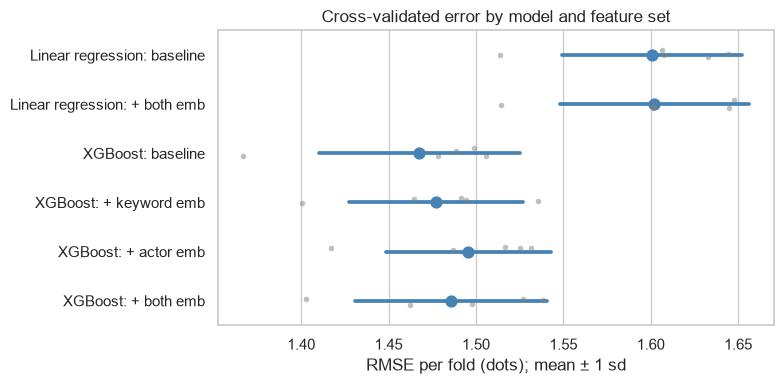

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
order = list(runs)
sns.pointplot(data=fold_scores, y="run", x="RMSE", order=order, errorbar="sd",
              linestyles="none", color="steelblue", ax=ax)
sns.stripplot(data=fold_scores, y="run", x="RMSE", order=order, color="gray", alpha=0.5, size=4, ax=ax)
ax.set_ylabel("")
ax.set_xlabel("RMSE per fold (dots); mean ± 1 sd")
ax.set_title("Cross-validated error by model and feature set")
plt.tight_layout()

**Paired comparison.** All runs use the same folds, so we compare each embedding run with the XGBoost baseline fold by fold. A negative difference means the embeddings lowered the error.

In [19]:
wide = fold_scores.pivot(index="fold", columns="run", values="RMSE")
diff = pd.DataFrame({
    run: wide[run] - wide["XGBoost: baseline"]
    for run in ["XGBoost: + keyword emb", "XGBoost: + actor emb", "XGBoost: + both emb"]
})
diff.agg(["mean", "std", "min", "max"]).T.round(3).assign(
    folds_improved=(diff < 0).sum().astype(str) + " / 5")

,mean,std,min,max,folds_improved
XGBoost: + keyword emb,0.010,0.024,-0.014,0.037,2 / 5
XGBoost: + actor emb,0.028,0.018,0.009,0.050,0 / 5
XGBoost: + both emb,0.018,0.028,-0.016,0.040,2 / 5


## 7. Feature importance

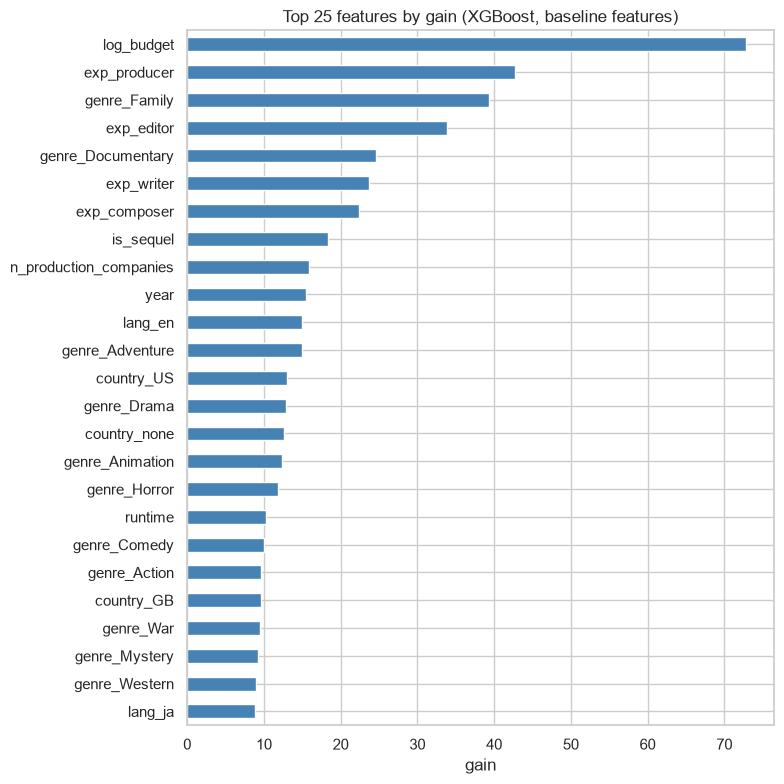

In [20]:
xgb_base = fit_xgb(X_dev[feature_sets["baseline"]], y_dev)
imp = pd.Series(xgb_base.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(25)

fig, ax = plt.subplots(figsize=(8, 8))
imp[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("gain")
ax.set_title("Top 25 features by gain (XGBoost, baseline features)")
plt.tight_layout()

## 8. Test set

Each model is refitted on all cross-validation films and scored once on the held-out test films.

In [21]:
test_scores, test_preds = {}, {}
for run, (kind, cols) in runs.items():
    model = make_linear().fit(X_dev[cols], y_dev) if kind == "linear" else fit_xgb(X_dev[cols], y_dev)
    test_preds[run] = model.predict(X_all.loc[te, cols])
    test_scores[run] = scores(y[te], test_preds[run])

test_res = pd.DataFrame(test_scores).T
test_res["RMSE vs linear"] = (1 - test_res["RMSE"] / test_res.loc["Linear regression: baseline", "RMSE"]).map("{:+.1%}".format)
test_res.round(3)

,RMSE,MAE,R2,RMSE vs linear
Linear regression: baseline,1.602,1.241,0.513,+0.0%
Linear regression: + both emb,1.595,1.235,0.517,+0.5%
XGBoost: baseline,1.438,1.099,0.608,+10.3%
XGBoost: + keyword emb,1.469,1.123,0.590,+8.3%
XGBoost: + actor emb,1.489,1.152,0.579,+7.1%
XGBoost: + both emb,1.489,1.151,0.579,+7.1%


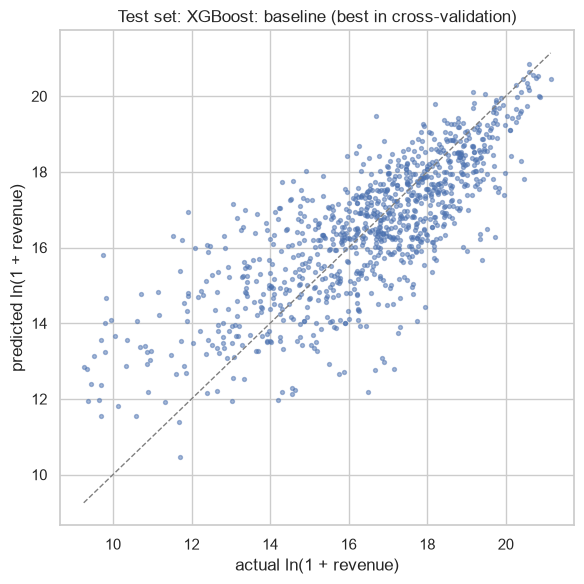

In [22]:
best_run = summary[("RMSE", "mean")].idxmin()
pred = test_preds[best_run]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y[te], pred, s=8, alpha=0.5)
lims = [min(y[te].min(), pred.min()), max(y[te].max(), pred.max())]
ax.plot(lims, lims, color="gray", ls="--", lw=1)
ax.set_xlabel("actual ln(1 + revenue)")
ax.set_ylabel("predicted ln(1 + revenue)")
ax.set_title(f"Test set: {best_run} (best in cross-validation)")
plt.tight_layout()